# Week9; Using AI reasoning for scientific discovery
**GGS 662 Agentic GeoAI | AI reasoning for scientific discovery**

**Research question: How do we accurately predict electrical towers from aerial imagery?**

We will start with labelled images and a deliberately small (and limited) baseline to train a model and measure its predictions against reference truth data. 

Next, we will hand over the task to a coding agent and set it the challenge of maximizing the mean average precision (mAP) through feature engineering, hyperparameter tuning, and method/model selection.

For this pre-existing topic, we will not be getting into formal hypothesis writing. Here, it will be the agent that eventually chooses, runs and evaluates changes using validation feedback. 

Our final evidence (which a human will need to review) is the measured improvement over a preserved baseline, under a fixed evaluation protocol.

This local VS Code lesson uses the data already in this repository. Run cells in order with the `.venv` Python kernel. Installation instructions are in `README.md`.

The first set of model weights will require the internet to download. The notebook does not call an agent API, instead for now, you will pass the prompt in Section 7 to your existing coding agent (e.g., in the VS Code agents panel).

## 1. A short introduction to object detection

Imagine an aerial photograph containing roads, buildings, trees and a few electricity transmission towers. 

**Object detection** asks a model to identify objects and draw a rectangle, called a **bounding box**, around each one. 

For this exercise, the only object class will be electrical towers. Of course, each image could contain more than one tower, so the model may need to predict several boxes. 

Predicting object classes and bounding boxes jointly is the central idea illustrated by the original YOLO detector ([Redmon et al., 2016](https://www.cv-foundation.org/openaccess/content_cvpr_2016/papers/Redmon_You_Only_Look_CVPR_2016_paper.pdf)). This is a foundational reference, although the implementation used here is the later YOLOv8 model (not designed by Redmon).

### Why electrical towers?

Detecting towers can contribute to mapping electricity infrastructure from imagery. For example, **GridTracer** investigates tower recognition and power line connections in overhead imagery, making it a close application reference for this lesson ([Huang et al., 2022](https://doi.org/10.1109/JSTARS.2021.3124519)). Detecting a tower is one step toward a network map, but of course a set of object boxes does not by itself establish which towers are connected (which is a harder task and not really one that imagery can help with currently).

Additionally, the **TTPLA** dataset provides aerial images with manually annotated transmission towers and power lines, together with deep learning detection and segmentation baselines ([Abdelfattah et al., 2020](https://openaccess.thecvf.com/content/ACCV2020/html/Abdelfattah_TTPLA_An_Aerial-Image_Dataset_for_Detection_and_Segmentation_of_Transmission_ACCV_2020_paper.html)). The dataset illustrates how reference annotations support learning and evaluation for this specific application. Imagery and viewpoints differ across studies, so their reported scores are not directly comparable with our 110-image exercise.

These papers supply application context.

### How does the model learn?

We provide two things: **imagery** and **reference annotations**, often called *ground truth* or *truth data*. Each annotation tells the model where a tower is in an image. 

During training, the model compares its predictions with these annotations and adjusts its internal parameters to reduce errors. We are basically teaching a statistical model visual patterns associated with towers, as opposed to trying to write a hand written set of formal rules for every possible tower. 

Large annotated benchmarks such as COCO illustrate this use of reference object annotations for detection research ([Lin et al., 2014](https://people.cs.uchicago.edu/~mmaire/papers/pdf/coco_eccv2014.pdf)).

The annotations are our best available answers, not perfect truth. Of course, people can still miss objects or draw inaccurate boxes. 

### How do we know whether its predictions are useful?

A model can learn its training examples without working well on other images. We therefore divide the labelled images into three separate groups:

| Group | What we use it for |
| --- | --- |
| **Training** | Learn patterns from imagery and the supplied boxes. |
| **Validation** | Predict boxes for held-out images, compare with their reference boxes, and choose improvements. |
| **Final test** | Evaluate the selected method once on images that did not guide those choices. |

For validation and testing, the model receives the image, not its reference boxes. The evaluator then compares the predicted boxes with the reference boxes. A useful detector must both **find the towers** and **place its boxes accurately**, while avoiding false alarms.

We summarize this predictive effectiveness with **mean average precision (mAP)**, explained in Section 3. Higher mAP means better agreement with the reference annotations under the same evaluation rules.

### Where does AI reasoning enter?

The detector learns to recognize towers. Separately, a **coding agent** will reason about how to improve that detector. So, this agent can change preprocessing/features, tune training settings, or choose a different model, then run the experiment and read its validation score. The human fixes the reference data and scoring rule, whereas the agent searches for the pipeline with the highest validation mAP.

This is a small example of AI-assisted empirical discovery. The evidence is measured as predictive improvement. We do not require formal hypothesis writing, and a higher score alone does not establish a physical explanation or performance in every geographic setting.

## 2. Use real imagery and reference boxes

The bundled dataset is `week9/data/demo100`: **50 training, 10 validation, and 50 final-test images**, each with matching YOLO labels. The folder name is retained from the original 50/50 training/test bundle; ten validation images were added to support agent tuning without touching test data.

These are original JPEGs selected from the source dataset's separate train, validation and test folders, with sampling spread across parent scenes (kudos to Dante Groccia for the labeling and previous research on this topic). 




In [7]:
from pathlib import Path
import sys, json, time, platform
START = Path.cwd().resolve()
ROOT = next((root for parent in (START, *START.parents)
             for root in (parent, parent/'week9')
             if (root/'scripts/prepare_demo.py').is_file()
             and (root/'data/demo100/manifest.json').is_file()), None)
assert ROOT is not None, 'Launch from Agentic-GeoAI, week9, or week9/notebooks'
sys.path.insert(0, str(ROOT))
from scripts.prepare_demo import prepare
DATA = prepare(ROOT)
manifest = json.loads((DATA / 'manifest.json').read_text())
print({s: sum(r['split'] == s for r in manifest['records']) for s in ['train','val','test']})

{'train': 50, 'val': 10, 'test': 50}


### Read a bounding box label

Each line is `class x_center y_center width height`. The four coordinates are fractions of image dimensions, rather than pixel coordinates. One image can contain multiple labelled towers. The red rectangles below are supplied annotations, not predictions. We inspect only training images here.

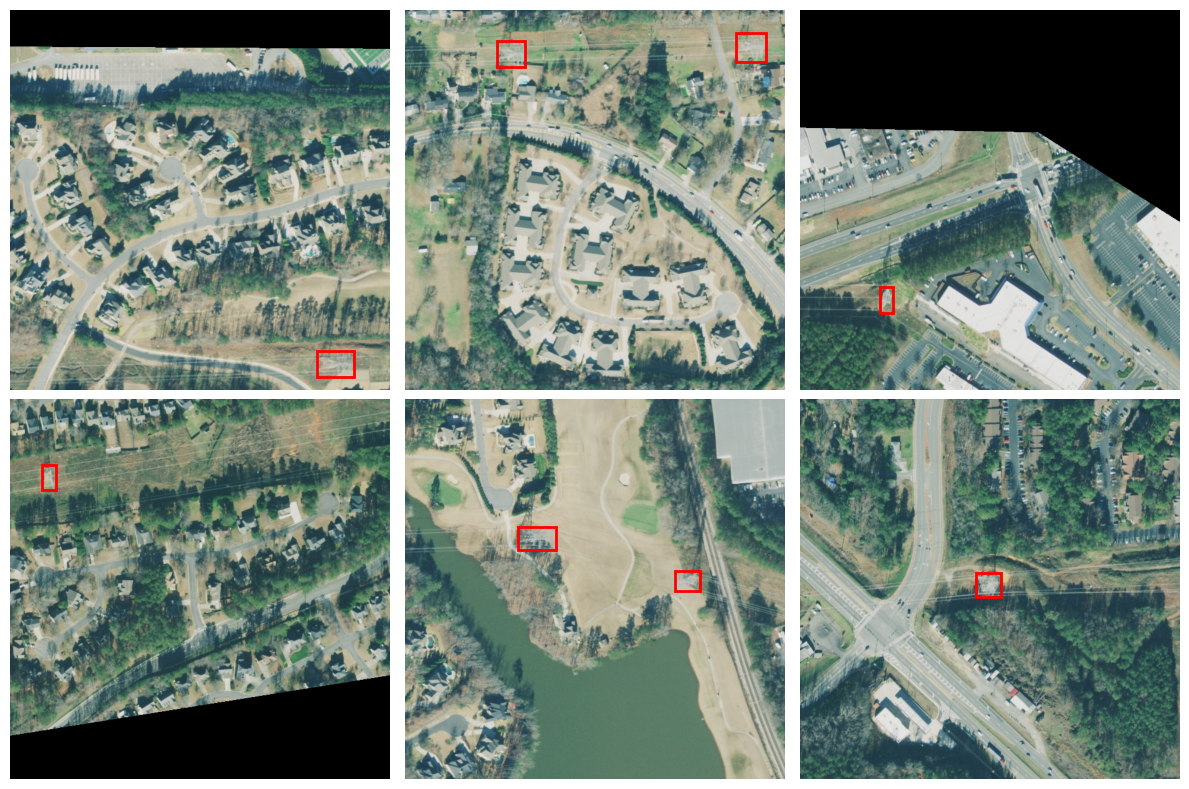

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

def draw_labels(ax, path):
    im = Image.open(path).convert('RGB')
    ax.imshow(im)
    w, h = im.size
    label = DATA / 'labels' / path.parent.name / (path.stem + '.txt')
    for line in label.read_text().splitlines():
        cls, x, y, bw, bh = map(float, line.split())
        ax.add_patch(Rectangle(((x-bw/2)*w, (y-bh/2)*h), bw*w, bh*h,
                               fill=False, edgecolor='red', linewidth=2))
    ax.axis('off')

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, path in zip(axes.flat, sorted((DATA/'images/train').glob('*.jpg'))[:6]):
    draw_labels(ax, path)
plt.tight_layout()

## 3. How do we measure a better prediction? Understanding mAP

A detector predicts a bounding box and a **confidence score** for each object it finds. Confidence lets us rank detections from most to least certain, but it is not a guarantee that a prediction is correct.

### Did the box land in the right place?

**Intersection over Union (IoU)** measures how much a predicted box overlaps a reference box:

**IoU = area of overlap / area covered by either box.**

IoU is 1 for identical boxes and 0 for boxes that do not overlap. At an IoU threshold of 0.50, a prediction must overlap its reference sufficiently to count as a correct match. Matches also require the correct class. Each reference tower can match only one prediction, so duplicate detections count as false alarms.

### Did we find towers without too many false alarms?

- **Precision:** of the towers the model predicted, how many were correct? If it predicts 10 and 8 match reference towers, precision is 8/10 = **80%**.
- **Recall:** of the reference towers, how many did it find? If there are 12 reference towers and it finds 8, recall is 8/12 = **67%**.

These numbers depend on the confidence cutoff. Keeping only confident predictions can remove false alarms but can also discard real towers. Lowering the cutoff can find more towers while adding false alarms.

### Summarize performance across cutoffs and box tolerances

**Average precision (AP)** summarizes the precision-recall curve as we vary the confidence cutoff. It rewards a detector that finds many reference objects while keeping precision high. It is not simply precision at one chosen cutoff.

**Mean average precision (mAP)** averages AP over object classes. Here there is only one class, tower, so this class average has just one term.

| Score | What it asks |
| --- | --- |
| **mAP50** | How well do we detect towers when a box match requires IoU of at least 0.50? |
| **mAP50-95** | How well do we detect towers across IoU thresholds 0.50, 0.55, ..., 0.95, including demanding requirements for box placement? |

The sequence of IoU thresholds follows the COCO evaluation convention ([COCO evaluation implementation](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py)). Our scores are calculated by the [Ultralytics validation implementation](https://docs.ultralytics.com/modes/val/), rather than by running the official COCO evaluator, so we should keep the same implementation and settings across experiments.

**Our agent's objective is to maximize validation mAP50-95.** Scores range from 0 to 1, and higher is better. A score of 0.20 is 20 mAP points, not a statement that 20% of images were correct. Improving from 0.20 to 0.30 is an absolute gain of 0.10, or 10 percentage points on this scale.

Precision, recall, mAP50 and runtime provide context, but do not replace the primary objective. The pictures use confidence >= 0.25 for readability. Evaluation uses a fixed low cutoff of 0.001 to retain ranked predictions for AP calculation.

Keep the same images, annotations and scoring protocol for every comparison. Repeated searching can overfit our ten validation images, which is why we reserve 50 images for a final test. 

## 4. Build one limited baseline

We fine-tune **YOLOv8 nano**, a small pretrained detector, for only 5 epochs at 320-pixel input resolution. This short budget and reduced image size leave room for improvement. 

The model learns visual features automatically. The agent can change the feature representation or preprocessing, tune training settings, or replace the detector. Handcrafted features are optional, so the existing RGB JPEGs do not provide a near-infrared (or other bands) for false composite images (e.g., NDVI).

Every run gets its own directory. Keep earlier outputs when the agent adds experiments. If you already ran the original notebook, its files remain under `runs/`; this revised runner creates a fresh baseline when executed.

In [9]:
import torch, ultralytics, hashlib, csv
from ultralytics import YOLO
SEED = 662
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
EXPERIMENTS = ROOT / 'experiments'
EXPERIMENTS.mkdir(exist_ok=True)
RESULTS = EXPERIMENTS / 'results.csv'
MANIFEST_HASH = hashlib.sha256((DATA/'manifest.json').read_bytes()).hexdigest()
# Keep the evaluation protocol fixed for all comparable runs.
EVAL = dict(conf=0.001, iou=0.7, max_det=300, augment=False)

def run_experiment(name, model_name='yolov8n.pt', epochs=5, imgsz=320,
                   batch=4, **training_options):
    forbidden = {'data', 'seed', 'project', 'name', 'exist_ok', 'device', 'workers', 'split'}
    if forbidden & training_options.keys():
        raise ValueError('Keep dataset, seed, split and run bookkeeping fixed')
    run = ROOT/'runs'/f"{name}_{time.strftime('%Y%m%d_%H%M%S')}_{time.time_ns() % 1000000}"
    run.mkdir(parents=True, exist_ok=False)
    environment = dict(python=platform.python_version(), torch=torch.__version__,
                       ultralytics=ultralytics.__version__, device=str(DEVICE), seed=SEED)
    options = dict(patience=5, plots=True, mosaic=0.0, cache=False)
    options.update(training_options)
    config = dict(model=model_name, epochs=epochs, imgsz=imgsz, batch=batch,
                  seed=SEED, manifest_sha256=MANIFEST_HASH, evaluation=EVAL, options=options)
    (run/'config.json').write_text(json.dumps(config, indent=2))
    (run/'environment.json').write_text(json.dumps(environment, indent=2))
    started = time.perf_counter()
    try:
        detector = YOLO(model_name)
        detector.train(data=str(DATA/'data.yaml'), epochs=epochs, imgsz=imgsz,
                       batch=batch, workers=0, device=DEVICE, seed=SEED,
                       project=str(run), name='train', exist_ok=False, **options)
        checkpoint = run/'train/weights/best.pt'
        fitted = YOLO(str(checkpoint))
        metrics = fitted.val(data=str(DATA/'data.yaml'), split='val', imgsz=imgsz,
                             batch=batch, workers=0, device=DEVICE, project=str(run),
                             name='validation', **EVAL)
        row = dict(run_id=run.name, status='ok', model=model_name, epochs=epochs,
                   imgsz=imgsz, seed=SEED, manifest_sha256=MANIFEST_HASH,
                   precision=float(metrics.box.mp), recall=float(metrics.box.mr),
                   mAP50=float(metrics.box.map50), mAP50_95=float(metrics.box.map),
                   seconds=time.perf_counter()-started, checkpoint=str(checkpoint),
                   config=str(run/'config.json'), error='')
    except Exception as exc:
        row = dict(run_id=run.name, status='failed', model=model_name, epochs=epochs,
                   imgsz=imgsz, seed=SEED, manifest_sha256=MANIFEST_HASH,
                   precision='', recall='', mAP50='', mAP50_95='',
                   seconds=time.perf_counter()-started, checkpoint='',
                   config=str(run/'config.json'), error=str(exc))
        raise
    finally:
        if 'row' in locals():
            (run/'metrics.json').write_text(json.dumps(row, indent=2))
            write_header = not RESULTS.exists() or RESULTS.stat().st_size == 0
            with RESULTS.open('a', newline='', encoding='utf-8') as handle:
                writer = csv.DictWriter(handle, fieldnames=list(row))
                if write_header: writer.writeheader()
                writer.writerow(row)
    print(row)
    return fitted, row

best, baseline = run_experiment('baseline')
BASELINE_CHECKPOINT = baseline['checkpoint']
print('Baseline validation mAP50-95:', baseline['mAP50_95'])

New https://pypi.org/project/ultralytics/8.4.198 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.23  Python-3.12.7 torch-2.10.0+cpu CPU (Intel Core i7-14700)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\eoughton\Desktop\Github\Agentic-GeoAI\week9\data\demo100\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0

## 5. Look at predictions and errors

Compare reference boxes on the left with predictions on the right. Missed towers, false alarms and poorly positioned boxes can suggest useful changes. The displayed confidence cutoff is 0.25, so the scored evaluation above uses 0.001. Changing the display cutoff does not change the recorded mAP.

Some things may limit this baseline, e.g., lost detail at 320 pixels, a short training schedule, weak contrast, or the feature representation/model. The agent can use these observations without writing a formal hypothesis.

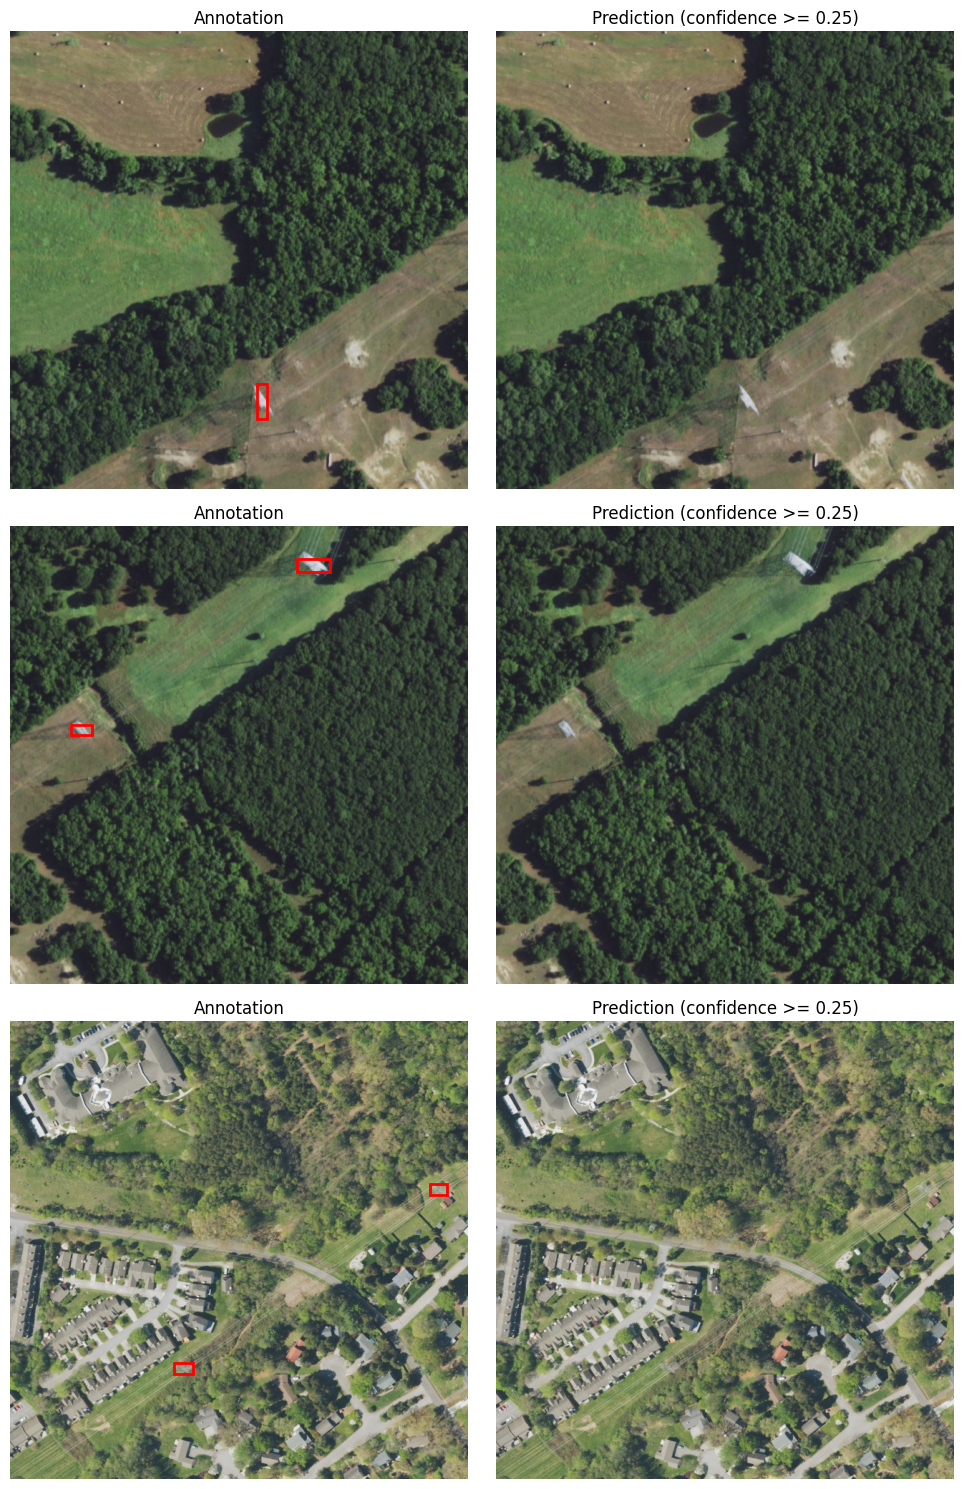

In [10]:
paths = sorted((DATA/'images/val').glob('*.jpg'))[:3]
predictions = best.predict(source=[str(p) for p in paths], imgsz=baseline['imgsz'],
                           conf=0.25, device=DEVICE, verbose=False)
fig, axes = plt.subplots(len(paths), 2, figsize=(10, 5*len(paths)))
for row, path, prediction in zip(axes, paths, predictions):
    draw_labels(row[0], path)
    row[0].set_title('Annotation')
    row[1].imshow(prediction.plot()[..., ::-1])
    row[1].set_title('Prediction (confidence >= 0.25)')
    row[1].axis('off')
plt.tight_layout()

## 6. Define the agent's search space

The objective stays fixed (e.g., improve mAP), but the agent chooses how to reach it.

| Area | Examples of allowed changes |
| --- | --- |
| Feature engineering / preprocessing | Contrast normalization, multiscale inputs, crops or tiling with correct box transforms, alternate learned representations |
| Hyperparameter tuning | Learning rate, optimizer, epochs, batch size, augmentation, frozen layers |
| Method / model selection | Larger YOLO variants or another detector with an adapter to the same scoring protocol |

Fit learned preprocessing only on training data. Apply the resulting pipeline consistently at validation/inference. For tiles, merge detections into original image coordinates before scoring each original validation image once. Compare alternate methods with the same class, reference boxes, AP implementation, IoU thresholds, NMS settings and detection limit. Image resolution may change as part of the predictive pipeline and must be recorded.

Use up to **6 additional training runs or 60 minutes of training**, whichever comes first. Set per-run limits to fit the remaining time. The goal is the highest measured validation mAP50-95 within this budget, not an exhaustive search. A short note on what changed is enough, as I do not expect you to do formal hypothesis testing.

## 7. Hand optimization to a coding agent

### Option 1: run from the Agents window (simplest for class)

1. Finish the baseline, save the notebook, and check that `experiments/results.csv` exists.
2. Open your coding assistant's **Agents/chat panel** in VS Code, or its desktop app, and select the `Agentic-GeoAI/week9` folder as the local workspace. For Codex, install/sign into the IDE extension if needed ([official setup](https://learn.chatgpt.com/docs/codex/ide)). Button names vary by assistant; choose a mode that can edit files and run local commands.
3. Start a new local task and paste the prompt below. Include `AGENT_HANDOFF.md` and the notebook as file context, or explicitly ask the agent to read them.
4. Tell it to use `.venv/Scripts/python.exe` on Windows (`.venv/bin/python` on macOS/Linux). It must read saved run files. An agent terminal does not inherit variables or trained models from the notebook kernel. It can extract/reuse the runner in a standalone experiment script.
5. Follow its progress and command requests. After it finishes, rerun Section 8 to compare recorded results, then review the report before enabling the final test.

Use a **local** task because these images are on your machine, so a remote/cloud agent will not automatically have them. Ask the agent to add experiment cells or a script, not run the whole notebook (run All would retrain the baseline).

### Task prompt

Copy the following prompt into your existing coding assistant after the baseline finishes. A single agent is sufficient. If you choose multiple agents, they share the same data and total compute budget. 

A coordinator maintains one results table and prevents concurrent writes (which we will use to compare runs).

> Work in `notebooks/09_tower_detection_agentic_demo.ipynb`. Maximize validation **mAP50-95** on the fixed 110-image tower dataset (50 training / 10 validation / 50 test). Read the notebook, baseline results and `AGENT_HANDOFF.md`. Choose and execute up to six additional training runs within 60 minutes of training. You may improve preprocessing/features, tune hyperparameters, or change detection methods/models. Use AI reasoning and measured validation feedback to select what to try next. No formal hypothesis development is required.
>
> Preserve the baseline and earlier results. Add experiment cells using `run_experiment` where compatible. Record exact settings, actual scores, failures and runtime in `experiments/results.csv`. For another method, use the same evaluation protocol and provide an adapter. Keep the raw data, reference labels, manifest, train/validation/test split, seed and primary metric fixed. Fit preprocessing only on training data. Never examine test images, tune on test scores, or execute the final-test cell.
>
> Select the highest measured validation mAP50-95, write its checkpoint and inference settings to `experiments/selected_model.json`, and summarize baseline versus best, absolute improvement, changes tried and limitations in `experiments/report.md`. If a run fails, record it. Do not invent scores. Do not upload data or use paid cloud compute. Stop at the budget. Do not start optimizing yet if the baseline is still running.

The prompt delegates execution when you send it. Running this notebook alone does not launch agents.

### Option 2: write a Python agent script (e.g., with Anthropic, OpenAI, etc.)

For a scripted coding agent, we can use something like Anthropic's **Claude Agent SDK** (`claude-agent-sdk`). It supplies the agent loop and tools for reading/editing files and running commands. The general **Anthropic Python SDK** (`anthropic`) calls the model API, but by itself it does not execute generated code. With that lower-level SDK, you would have to implement tool definitions, execution and the feedback loop yourself ([SDK overview](https://platform.claude.com/docs/en/cli-sdks-libraries/overview), [Agent SDK quickstart](https://code.claude.com/docs/en/agent-sdk/quickstart)).

Use Python 3.10+ and an Anthropic API account/key. The optional launcher is already provided as `scripts/run_claude_agent.py`. It reads our handoff and starts a local agent with file and terminal tools.

**On Windows, in the VS Code PowerShell terminal, from the `week9` folder:**

```powershell
.\.venv\Scripts\python -m pip install claude-agent-sdk
# Enter the key locally; do not paste it into the notebook or chat.
$agentKey = Read-Host "Anthropic API key" -AsSecureString
$env:ANTHROPIC_API_KEY = [System.Net.NetworkCredential]::new("", $agentKey).Password
.\.venv\Scripts\python scripts/run_claude_agent.py
Remove-Item Env:ANTHROPIC_API_KEY
```

On Windows the runtime may require Git Bash. Use the SDK's installation/troubleshooting guidance if it cannot find the shell or bundled executable. This route makes paid API calls and can send repository context to Anthropic. Running it is optional, as no SDK agent starts when you run notebook cells.

### What is inside the script?

```python
from claude_agent_sdk import ClaudeAgentOptions, query

options = ClaudeAgentOptions(
    cwd=str(ROOT),  # this repository
    allowed_tools=["Read", "Write", "Edit", "Glob", "Grep", "Bash"],
    permission_mode="acceptEdits",
    max_turns=40,
    max_budget_usd=5.0,
)
async for message in query(prompt=assignment, options=options):
    print(message)
```

The complete script builds `assignment` from `AGENT_HANDOFF.md` and tells the agent to use the same Python environment. The SDK handles the cycle, so the model chooses an action, tool runs, result returns, etc., and then chooses its next action. `acceptEdits` handles file edits. 

`max_turns` and the estimated $5 API budget limit the agent session. The dollar limit can be exceeded slightly and is separate from the six-run/60-minute training budget in the assignment ([Python SDK options](https://code.claude.com/docs/en/agent-sdk/python)). That training budget and the sealed-test rule are instructions, not hard filesystem or process isolation. Watch the run during this classroom demo.

**Choose only one route for a search.** So, do not launch both at once against the same results CSV. The two routes use the same reference data, objective, budget and deliverables. Only the way we start the coding agent changes. I recommend you use option 1 today. 

### Extension lab: can more varied training views improve mAP?

**Data augmentation** makes transformed versions of training images, such as left/right flips, up/down flips or rotations. The bounding boxes must undergo the same geometric transformation. Ultralytics provides transforms that handle images and boxes together ([augmentation guide](https://docs.ultralytics.com/guides/yolo-data-augmentation/)).

There are two ways to provide more training views:

- **Online augmentation:** transform images randomly when a training batch is loaded. Our 50 training files remain 50 files, but the model sees different views across epochs. This is the simplest route here.
- **Offline augmentation:** save transformed images and matching labels. For example, keeping each original plus three variants gives 200 training files from 50 source tiles. It still represents only 50 source tiles. A larger training folder also changes the number of updates per epoch, so record both compute and sample exposure.

The bundled dataset uses original images rather than saved augmentation variants. Additional augmentation is not guaranteed to help. So, strong rotations can clip edge towers or change aligned boxes, and small objects can lose detail. Keep validation and test images unchanged. Do not copy augmentation siblings from the original archive across the fixed splits.

#### First audit what actually happened

A small model is not automatically an unaugmented model. YOLO can apply training transforms by default. Inspect the saved **training `args.yaml`** as well as our requested `config.json`. The evaluation flag `augment=False` disables inference-time augmentation. 

In the completed example, `opt06_adamw640` requested `fliplr=0.5`, `degrees=5`, `mosaic=0.25` and `mixup=0.1`. Thus it already used augmentation; the original CSV simply did not show those settings. The audit below reads your actual local runs rather than assuming the same experiment names exist.

In [11]:
import yaml
with RESULTS.open(newline='', encoding='utf-8') as handle:
    audit_rows = list(csv.DictReader(handle))
augmentation_keys = ['fliplr', 'flipud', 'degrees', 'translate', 'scale',
                     'shear', 'perspective', 'hsv_h', 'hsv_s', 'hsv_v',
                     'mosaic', 'mixup', 'cutmix', 'copy_paste']
for row in audit_rows:
    if row['status'] != 'ok':
        continue
    config_path = Path(row['config'])
    args_path = config_path.parent/'train/args.yaml'
    if not args_path.exists():
        print(row['run_id'], ': saved training args unavailable')
        continue
    actual = yaml.safe_load(args_path.read_text(encoding='utf-8'))
    settings = {key: actual.get(key, 'not recorded') for key in augmentation_keys}
    print(row['run_id'], 'mAP50-95 =', row['mAP50_95'])
    print(settings)


baseline_20261102_155320_890400 mAP50-95 = 0.00042596022123156586
{'fliplr': 0.5, 'flipud': 0.0, 'degrees': 0.0, 'translate': 0.1, 'scale': 0.5, 'shear': 0.0, 'perspective': 0.0, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4, 'mosaic': 0.0, 'mixup': 0.0, 'cutmix': 0.0, 'copy_paste': 0.0}
baseline_20261102_182515_382900 mAP50-95 = 0.00042596022123156586
{'fliplr': 0.5, 'flipud': 0.0, 'degrees': 0.0, 'translate': 0.1, 'scale': 0.5, 'shear': 0.0, 'perspective': 0.0, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4, 'mosaic': 0.0, 'mixup': 0.0, 'cutmix': 0.0, 'copy_paste': 0.0}


## 8. Agent-run optimization experiments (logged)
Run these after baseline finishes. They preserve fixed data/seed/eval settings and append to `experiments/results.csv`.

In [ ]:
# Toggle this on only when you want to re-run the optimization search.
RUN_AGENT_SEARCH = False

if RUN_AGENT_SEARCH:
    # 6 additional trials used in this handoff (failures count toward budget)
    run_experiment('exp01_yolov8n_e30_img640', model_name='yolov8n.pt', epochs=30, imgsz=640, batch=4, patience=10)
    run_experiment('exp02_resume_e30_img640', model_name=BASELINE_CHECKPOINT, epochs=30, imgsz=640, batch=4, patience=10)
    run_experiment('exp03_resume_e30_img640', model_name=BASELINE_CHECKPOINT, epochs=30, imgsz=640, batch=4, patience=10)
    run_experiment('exp04_adamw_lr003_e40_img640', model_name=BASELINE_CHECKPOINT, epochs=40, imgsz=640, batch=4,
                   patience=12, optimizer='AdamW', lr0=0.003, lrf=0.2, weight_decay=0.001)
    run_experiment('exp05_sgd_e45_img640', model_name=BASELINE_CHECKPOINT, epochs=45, imgsz=640, batch=4, patience=15)
    run_experiment('exp06_finetune_from_exp05',
                   model_name=str(ROOT/'runs/exp05_sgd_e45_img640_20261103_072626_839500/train/weights/best.pt'),
                   epochs=20, imgsz=640, batch=4, patience=8, lr0=0.002, lrf=0.1)


In [ ]:
# Quick leaderboard from recorded results (no test evaluation)
import csv
with RESULTS.open(newline='', encoding='utf-8') as f:
    rows = [r for r in csv.DictReader(f) if r['status']=='ok' and r['mAP50_95']]
rows = sorted(rows, key=lambda r: float(r['mAP50_95']), reverse=True)
for r in rows[:8]:
    print(r['run_id'], 'mAP50-95=', r['mAP50_95'], 'seconds=', r['seconds'])


#### Student task: extend the agent's capabilities, then integrate the results

Run this as a **second assignment** after the first optimization finishes. Give the following prompt to your local agent window. It adds a new budget; it does not silently extend the first six-run assignment.

> Read `AUGMENTATION_HANDOFF.md`. Execute the augmentation extension now: audit existing training settings, then run up to three additional matched trials (30 minutes of training total) comparing explicit no-additional-augmentation, flips, and flips plus rotations. Use the same initial checkpoint and other training settings for every trial. Keep the existing source-tile split and evaluation protocol fixed. Preserve earlier results and append runs prefixed `aug_` to the existing CSV. Do not inspect test data. Report whether augmentation improves validation mAP50-95; a negative result is acceptable. Do not claim it helped solely because a longer training run improved.

The agent should reuse `scripts/run_experiment_once.py`, which accepts repeated `--set key=value` arguments. For example, `--set fliplr=0.5 --set flipud=0.5 --set degrees=15` requests random flips and rotations within ?15 degrees. This example sets only these three options; the agent must explicitly control the other transforms for a fair comparison.

After the agent finishes, rerun the audit and Section 8. Read `experiments/augmentation_report.md` for the matched comparison. Integrate the winning pipeline only if its measured validation mAP50-95 exceeds the incumbent. Keep all failed and lower-scoring trials in the record. This extension builds the workflow in stages: first optimize a detector, then add and evaluate a specific capability.

## Discussion and a short research briefing

Prepare a five-minute explanation with the annotation/prediction examples and results chart:

1. What are our reference labels and what does the detector predict?
2. What was the baseline mAP50-95 and what did the agent achieve?
3. Which feature, tuning or model choices were actually tried?
4. What can these results establish, and what needs a larger spatially independent test?

An improvement in prediction is an empirical finding under this protocol. It does not prove label correctness, establish a physical explanation, or demonstrate performance on tower-free imagery or other regions.

## References

### Object detection and evaluation

- Redmon, J., Divvala, S., Girshick, R., & Farhadi, A. (2016). *You Only Look Once: Unified, Real-Time Object Detection*. Proceedings of CVPR, 779?788. [Open-access paper](https://www.cv-foundation.org/openaccess/content_cvpr_2016/papers/Redmon_You_Only_Look_CVPR_2016_paper.pdf). Foundational explanation of predicting classes and bounding boxes with one neural network; not a paper describing YOLOv8.
- Lin, T.-Y., Maire, M., Belongie, S., Hays, J., Perona, P., Ramanan, D., Doll?r, P., & Zitnick, C. L. (2014). *Microsoft COCO: Common Objects in Context*. ECCV, 740?755. [Author-hosted paper](https://people.cs.uchicago.edu/~mmaire/papers/pdf/coco_eccv2014.pdf). Background on annotated object-recognition benchmarks.
- COCO Consortium. *COCO detection evaluation implementation*. [Official source](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py). Reference for AP evaluation across IoU thresholds 0.50?0.95.

### Electricity infrastructure applications

- Huang, B., Yang, J., Streltsov, A., Bradbury, K., Collins, L. M., & Malof, J. M. (2022). *GridTracer: Automatic Mapping of Power Grids Using Deep Learning and Overhead Imagery*. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 15, 4956?4970. [DOI](https://doi.org/10.1109/JSTARS.2021.3124519); [open preprint](https://arxiv.org/abs/2101.06390). Direct context for tower recognition and grid connectivity from overhead imagery.
- Abdelfattah, R., Wang, X., & Wang, S. (2020). *TTPLA: An Aerial-Image Dataset for Detection and Segmentation of Transmission Towers and Power Lines*. Proceedings of ACCV. [Conference paper](https://openaccess.thecvf.com/content/ACCV2020/html/Abdelfattah_TTPLA_An_Aerial-Image_Dataset_for_Detection_and_Segmentation_of_Transmission_ACCV_2020_paper.html); [open preprint](https://arxiv.org/abs/2010.10032). Application-specific annotated dataset and detection/segmentation baselines.

### Teaching materials, implementation and local data

- [GGS 662 Agentic GeoAI course](https://github.com/edwardoughton/Agentic-GeoAI), especially [Week 7B: land-cover classification](https://github.com/edwardoughton/Agentic-GeoAI/blob/main/07_02_agentic_land_cover_classification.ipynb). Adapted teaching structure: question, reference data, baseline, agent investigation, comparison and final test.
- [Ultralytics Python API](https://docs.ultralytics.com/usage/python/) and [validation metrics](https://docs.ultralytics.com/modes/val/).
- Local `naip_towers_v1` imagery and annotations supplied for this exercise; external source and annotation provenance remain to be documented.